In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import torch
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    Trainer, TrainingArguments, DataCollatorWithPadding, EarlyStoppingCallback,
)
from datasets import Dataset
from sklearn.metrics import accuracy_score, f1_score, classification_report

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IS_COLAB = True
except ImportError:
    IS_COLAB = False

if IS_COLAB:
    %pip install -q transformers datasets accelerate

# === EDIT THESE PATHS ===
if IS_COLAB:
    PROJECT_ROOT = Path("/content/drive/MyDrive/thesis_stage2")
else:
    PROJECT_ROOT = Path(".")

PROCESSED_DIR = PROJECT_ROOT
MODELS_DIR    = PROJECT_ROOT / "models"
RESULTS_DIR   = PROJECT_ROOT / "results"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# === HYPERPARAMETERS (match 4.4.5) ===
MODEL_NAME    = "roberta-base"
SEED          = 42
MAX_LEN       = 512
LR            = 2e-5
WEIGHT_DECAY  = 0.01
EPOCHS        = 10
BATCH_TRAIN   = 16
BATCH_EVAL    = 32
WARMUP_RATIO  = 0.1
GRAD_CLIP     = 1.0
EARLY_STOP    = 3

OUT_DIR = MODELS_DIR / "joint11_combined_pr_tqa"
print(f"Output: {OUT_DIR}")

Mounted at /content/drive
Output: /content/drive/MyDrive/thesis_stage2/models/joint11_combined_pr_tqa


In [2]:
# === Unified 11-class label space (PR's long-form names) ===
LABEL_SPACE = [
    "No Distortion",
    "Black-and-white or polarized thinking / All or nothing thinking",
    "Catastrophizing",
    "Discounting the positive",
    "Jumping to conclusions: Fortune-telling",
    "Jumping to conclusions: mind reading",
    "Labeling and mislabeling",
    "Mental filtering",
    "Overgeneralization",
    "Personalization",
    "Should statements",
]
LABEL_TO_IDX = {lbl: i for i, lbl in enumerate(LABEL_SPACE)}

# === TQA -> PR label mapping ===
# Same mapping used in earlier cross-corpus diagnostics.
TQA_TO_PR = {
    "No Distortion":            "No Distortion",
    "All-or-nothing thinking":  "Black-and-white or polarized thinking / All or nothing thinking",
    "Emotional Reasoning":      None,  # dropped — no PR equivalent
    "Fortune-telling":          "Jumping to conclusions: Fortune-telling",
    "Labeling":                 "Labeling and mislabeling",
    "Magnification":            "Catastrophizing",
    "Mental filter":            "Mental filtering",
    "Mind Reading":             "Jumping to conclusions: mind reading",
    "Overgeneralization":       "Overgeneralization",
    "Personalization":          "Personalization",
    "Should statements":        "Should statements",
}


def load_pr_split(name):
    """Load augmented PatternReframe split (v1_balanced)."""
    df = pd.read_csv(PROCESSED_DIR / f"patternreframe_{name}_aug_v1_balanced.csv")
    df = df.copy()
    df["text"] = df["thought"].astype(str)
    df["label_str"] = df["pattern"]
    df["source"] = "PR"
    return df[["text", "label_str", "source"]]


def load_tqa_split(name):
    """Load TQA split and map labels to PR space, dropping Emotional Reasoning."""
    df = pd.read_csv(PROCESSED_DIR / f"therapistqa_{name}.csv")
    df = df.copy()
    df["text"] = df["patient_question"].astype(str)
    df["label_str"] = df["dominant_distortion"].map(TQA_TO_PR)
    df["source"] = "TQA"
    n_before = len(df)
    df = df.dropna(subset=["label_str"]).reset_index(drop=True)
    n_dropped = n_before - len(df)
    if n_dropped:
        print(f"  TQA {name}: dropped {n_dropped} records (Emotional Reasoning)")
    return df[["text", "label_str", "source"]]


# === Build combined splits ===
def build_combined(name):
    pr = load_pr_split(name)
    tqa = load_tqa_split(name)
    combined = pd.concat([pr, tqa], ignore_index=True)
    combined = combined.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
    combined["label"] = combined["label_str"].map(LABEL_TO_IDX)
    assert combined["label"].notna().all(), "Unmapped label found"
    combined["label"] = combined["label"].astype(int)
    return combined


print("Building combined splits...")
train_df = build_combined("train")
val_df   = build_combined("val")
test_df  = build_combined("test")

print(f"\nCombined train: {len(train_df)} (PR {(train_df.source=='PR').sum()}, "
      f"TQA {(train_df.source=='TQA').sum()})")
print(f"Combined val:   {len(val_df)} (PR {(val_df.source=='PR').sum()}, "
      f"TQA {(val_df.source=='TQA').sum()})")
print(f"Combined test:  {len(test_df)} (PR {(test_df.source=='PR').sum()}, "
      f"TQA {(test_df.source=='TQA').sum()})")

print(f"\nTrain label distribution:")
for lbl in LABEL_SPACE:
    n = (train_df["label_str"] == lbl).sum()
    print(f"  {lbl:60s}  {n}")

Building combined splits...
  TQA train: dropped 94 records (Emotional Reasoning)
  TQA val: dropped 20 records (Emotional Reasoning)
  TQA test: dropped 20 records (Emotional Reasoning)

Combined train: 3786 (PR 2112, TQA 1674)
Combined val:   1416 (PR 1057, TQA 359)
Combined test:  7847 (PR 7488, TQA 359)

Train label distribution:
  No Distortion                                                 844
  Black-and-white or polarized thinking / All or nothing thinking  257
  Catastrophizing                                               336
  Discounting the positive                                      194
  Jumping to conclusions: Fortune-telling                       300
  Jumping to conclusions: mind reading                          364
  Labeling and mislabeling                                      311
  Mental filtering                                              271
  Overgeneralization                                            364
  Personalization                                

In [3]:
import torch.nn as nn

# === Class weights ===
counts = train_df["label"].value_counts().sort_index().reindex(
    range(len(LABEL_SPACE)), fill_value=1
).values
inv = 1.0 / counts
class_weights = torch.tensor(
    inv * (len(LABEL_SPACE) / inv.sum()), dtype=torch.float
)
print(f"Class weights:")
for i, lbl in enumerate(LABEL_SPACE):
    print(f"  [{i}] {lbl:60s}  weight={class_weights[i]:.3f}")


# === Tokenize ===
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LEN)


ds_train = Dataset.from_pandas(train_df[["text", "label"]]).map(tokenize, batched=True)
ds_val   = Dataset.from_pandas(val_df[["text", "label"]]).map(tokenize, batched=True)
ds_test  = Dataset.from_pandas(test_df[["text", "label"]]).map(tokenize, batched=True)
ds_train = ds_train.remove_columns(["text"])
ds_val   = ds_val.remove_columns(["text"])
ds_test  = ds_test.remove_columns(["text"])

Class weights:
  [0] No Distortion                                                 weight=0.359
  [1] Black-and-white or polarized thinking / All or nothing thinking  weight=1.179
  [2] Catastrophizing                                               weight=0.902
  [3] Discounting the positive                                      weight=1.561
  [4] Jumping to conclusions: Fortune-telling                       weight=1.010
  [5] Jumping to conclusions: mind reading                          weight=0.832
  [6] Labeling and mislabeling                                      weight=0.974
  [7] Mental filtering                                              weight=1.118
  [8] Overgeneralization                                            weight=0.832
  [9] Personalization                                               weight=1.041
  [10] Should statements                                             weight=1.193


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/3786 [00:00<?, ? examples/s]

Map:   0%|          | 0/1416 [00:00<?, ? examples/s]

Map:   0%|          | 0/7847 [00:00<?, ? examples/s]

In [5]:
class WeightedTrainer(Trainer):
    def __init__(self, class_weights=None, **kwargs):
        super().__init__(**kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        weight = self.class_weights.to(outputs.logits.device) if self.class_weights is not None else None
        loss = nn.CrossEntropyLoss(weight=weight)(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1_weighted": f1_score(labels, preds, average="weighted", zero_division=0),
        "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
    }


model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(LABEL_SPACE),
    id2label={i: lbl for i, lbl in enumerate(LABEL_SPACE)},
    label2id={lbl: i for i, lbl in enumerate(LABEL_SPACE)},
)

training_args = TrainingArguments(
    output_dir="/content/trainer_tmp" if IS_COLAB else str(OUT_DIR),
    num_train_epochs=EPOCHS,
    learning_rate=LR,
    weight_decay=WEIGHT_DECAY,
    per_device_train_batch_size=BATCH_TRAIN,
    per_device_eval_batch_size=BATCH_EVAL,
    warmup_ratio=WARMUP_RATIO,
    max_grad_norm=GRAD_CLIP,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_weighted",
    greater_is_better=True,
    save_total_limit=1,
    seed=SEED,
    report_to=[],
    logging_steps=50,
)

trainer = WeightedTrainer(
    class_weights=class_weights,
    model=model,
    args=training_args,
    train_dataset=ds_train,
    eval_dataset=ds_val,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=EARLY_STOP)],
)

trainer.train()

# Save the final model to Drive
trainer.save_model(str(OUT_DIR / "best"))
tokenizer.save_pretrained(str(OUT_DIR / "best"))
print(f"Saved to {OUT_DIR / 'best'}")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
classifier.out_proj.bias        | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.weight         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Weighted,F1 Macro
1,2.274015,1.769347,0.409605,0.393721,0.388364
2,1.586084,1.406574,0.547316,0.546001,0.539630
3,1.267703,1.356647,0.581921,0.573454,0.565521
4,0.956457,1.392038,0.556497,0.556167,0.548966
5,0.772954,1.527082,0.564266,0.560964,0.551825
6,0.516670,1.602048,0.565678,0.562981,0.552846


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to /content/drive/MyDrive/thesis_stage2/models/joint11_combined_pr_tqa/best


In [6]:
test_metrics = trainer.evaluate(ds_test)
print(f"Combined test metrics:")
for k, v in test_metrics.items():
    print(f"  {k}: {v}")

# Predict and break down by source
pred_out = trainer.predict(ds_test)
preds = np.argmax(pred_out.predictions, axis=-1)

test_df = test_df.copy()
test_df["pred"] = preds
test_df["pred_label"] = test_df["pred"].map(lambda i: LABEL_SPACE[int(i)])

print("\nMetrics by source:")
for source in ["PR", "TQA"]:
    sub = test_df[test_df["source"] == source]
    wf1 = f1_score(sub["label"], sub["pred"], average="weighted",
                   labels=list(range(len(LABEL_SPACE))), zero_division=0)
    mf1 = f1_score(sub["label"], sub["pred"], average="macro",
                   labels=list(range(len(LABEL_SPACE))), zero_division=0)
    acc = (sub["pred"] == sub["label"]).mean()
    print(f"\n  {source} ({len(sub)} records):")
    print(f"    Accuracy: {acc:.4f}")
    print(f"    Weighted F1: {wf1:.4f}")
    print(f"    Macro F1: {mf1:.4f}")

print("\nFull classification report:")
print(classification_report(
    test_df["label"], test_df["pred"],
    labels=list(range(len(LABEL_SPACE))),
    target_names=LABEL_SPACE, digits=4, zero_division=0,
))

Combined test metrics:
  eval_loss: 1.2409629821777344
  eval_accuracy: 0.6212565311584045
  eval_f1_weighted: 0.6166820201678406
  eval_f1_macro: 0.6152157630200775
  eval_runtime: 90.4884
  eval_samples_per_second: 86.718
  eval_steps_per_second: 2.719
  epoch: 6.0

Metrics by source:

  PR (7488 records):
    Accuracy: 0.6297
    Weighted F1: 0.6258
    Macro F1: 0.6274

  TQA (359 records):
    Accuracy: 0.4457
    Weighted F1: 0.4161
    Macro F1: 0.2513

Full classification report:
                                                                 precision    recall  f1-score   support

                                                  No Distortion     0.8373    0.8526    0.8449       821
Black-and-white or polarized thinking / All or nothing thinking     0.5702    0.4721    0.5165       680
                                                Catastrophizing     0.6057    0.6185    0.6121       755
                                       Discounting the positive     0.6508    0.7225  

Mean input length by predicted class:
                                                                  mean  median  count
pred_label                                                                           
Black-and-white or polarized thinking / All or nothing thinking   90.9    85.0    563
Catastrophizing                                                  112.5    85.0    771
Discounting the positive                                          89.7    87.0    756
Jumping to conclusions: Fortune-telling                          120.8    83.0    695
Jumping to conclusions: mind reading                             138.2    88.5    944
Labeling and mislabeling                                         130.4    79.0    498
Mental filtering                                                 127.1   107.0    511
No Distortion                                                    220.8   108.0    836
Overgeneralization                                               137.3    84.0    733
Personalization 

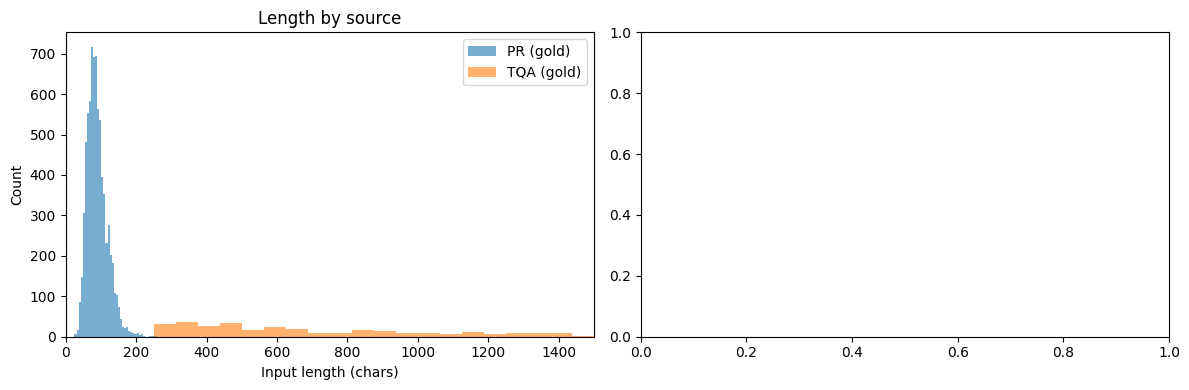

In [7]:
# Does the model's prediction correlate suspiciously with input length?
# If yes, the bimodal length distribution (PR ~80 chars, TQA ~500 chars) has
# become a shortcut feature for distinguishing the two corpora.

import matplotlib.pyplot as plt

test_df["length"] = test_df["text"].str.len()

# How does length distribution look by source vs by prediction?
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(test_df[test_df["source"]=="PR"]["length"], bins=40, alpha=0.6, label="PR (gold)")
axes[0].hist(test_df[test_df["source"]=="TQA"]["length"], bins=40, alpha=0.6, label="TQA (gold)")
axes[0].set_xlabel("Input length (chars)")
axes[0].set_ylabel("Count")
axes[0].set_title("Length by source")
axes[0].legend()
axes[0].set_xlim(0, 1500)

# Compute mean length per predicted class
length_by_pred = test_df.groupby("pred_label")["length"].agg(["mean", "median", "count"]).round(1)
print("Mean input length by predicted class:")
print(length_by_pred.to_string())

# Spearman correlation: input length vs prob of any TQA-specific category
# (TQA mostly has narrative-length inputs; if the model predicts TQA-style
# categories more on long input, that's a length shortcut)
nd_mask = test_df["pred_label"] == "No Distortion"
mean_len_nd = test_df.loc[nd_mask, "length"].mean()
mean_len_d  = test_df.loc[~nd_mask, "length"].mean()
print(f"\nMean length when predicted ND: {mean_len_nd:.0f}")
print(f"Mean length when predicted D:  {mean_len_d:.0f}")
print(f"Difference: {mean_len_d - mean_len_nd:.0f} chars")
print("(Large difference suggests length-based shortcut)")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "combined_length_diagnostic.png", dpi=150)
plt.show()

In [8]:
# === The 30-example deployment evaluation set ===
EXAMPLES = [
    # Obviously distorted
    ("distorted", "If I don't get this promotion, my whole career is a failure.", "All-or-nothing thinking"),
    ("distorted", "I made one mistake in the presentation and now everyone will think I'm incompetent.", "Catastrophizing"),
    ("distorted", "She said she liked my work but she was probably just being polite.", "Discounting the positive"),
    ("distorted", "I just know this date is going to go badly.", "Fortune-telling"),
    ("distorted", "He didn't text me back, so he must be angry with me.", "Mind reading"),
    ("distorted", "I forgot to send the email. I'm such an idiot.", "Labeling"),
    ("distorted", "Everyone clapped except for one person who looked bored. The whole talk was a disaster.", "Mental filtering"),
    ("distorted", "I bombed this job interview. I'm never going to find work.", "Overgeneralization"),
    ("distorted", "My partner is in a bad mood. It must be something I did.", "Personalization"),
    ("distorted", "I should be further along in my career by now.", "Should statements"),
    # Obviously non-distorted
    ("nondistorted", "I should call my mother this weekend.", "No Distortion"),
    ("nondistorted", "It looks like it might rain later.", "No Distortion"),
    ("nondistorted", "I have a meeting at 3pm tomorrow.", "No Distortion"),
    ("nondistorted", "The coffee tastes good today.", "No Distortion"),
    ("nondistorted", "I want to read more this year.", "No Distortion"),
    ("nondistorted", "My back hurts after sitting all day.", "No Distortion"),
    ("nondistorted", "I'm feeling tired and I think I'll go to bed early.", "No Distortion"),
    ("nondistorted", "The deadline is on Friday so I need to finish the report by Thursday.", "No Distortion"),
    ("nondistorted", "I disagreed with what she said but I understand her point.", "No Distortion"),
    ("nondistorted", "I made some progress today, though there's still more to do.", "No Distortion"),
    # Ambiguous
    ("ambiguous", "He didn't say hi to me at the meeting.", "uncertain"),
    ("ambiguous", "I'm worried I won't have enough money for retirement.", "uncertain"),
    ("ambiguous", "If the funding doesn't come through, the project is over.", "uncertain"),
    ("ambiguous", "My boss has been avoiding eye contact this week.", "uncertain"),
    ("ambiguous", "I shouldn't have lost my temper with him.", "uncertain"),
    ("ambiguous", "Given the market right now, jobs in my field are going to be hard to find.", "uncertain"),
    ("ambiguous", "I did well overall but I keep thinking about that one bad answer.", "uncertain"),
    ("ambiguous", "I don't think I'm qualified for this role.", "uncertain"),
    ("ambiguous", "The team missed the deadline and I was the lead.", "uncertain"),
    ("ambiguous", "Something doesn't feel right but I can't put my finger on what.", "uncertain"),
]

# Map casual expected names to long form
EXPECTED_TO_LONG = {
    "All-or-nothing thinking":  "Black-and-white or polarized thinking / All or nothing thinking",
    "Catastrophizing":          "Catastrophizing",
    "Discounting the positive": "Discounting the positive",
    "Fortune-telling":          "Jumping to conclusions: Fortune-telling",
    "Mind reading":             "Jumping to conclusions: mind reading",
    "Labeling":                 "Labeling and mislabeling",
    "Mental filtering":         "Mental filtering",
    "Overgeneralization":       "Overgeneralization",
    "Personalization":          "Personalization",
    "Should statements":        "Should statements",
    "No Distortion":            "No Distortion",
    "uncertain":                "uncertain",
}

# Predict on each
from torch.nn.functional import softmax
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device).eval()

rows = []
for intent, text, expected in EXAMPLES:
    enc = tokenizer(text, truncation=True, max_length=MAX_LEN, return_tensors="pt").to(device)
    with torch.no_grad():
        logits = model(**enc).logits
    probs = softmax(logits, dim=-1).cpu().numpy()[0]
    pred_idx = int(np.argmax(probs))
    pred_label = LABEL_SPACE[pred_idx]
    max_prob = float(probs[pred_idx])
    second_idx = int(np.argsort(-probs)[1])
    second_label = LABEL_SPACE[second_idx]
    second_prob = float(probs[second_idx])

    long_expected = EXPECTED_TO_LONG[expected]
    if expected == "uncertain":
        agreement = "ambiguous"
    elif pred_label == long_expected:
        agreement = "✓ match"
    else:
        agreement = "✗ different"

    rows.append({
        "Intent": intent,
        "Thought": text[:60] + "..." if len(text) > 60 else text,
        "Expected": expected,
        "Predicted": pred_label,
        "Confidence": f"{max_prob:.2f}",
        "2nd": second_label,
        "2nd conf": f"{second_prob:.2f}",
        "Agreement": agreement,
    })

deployment_df = pd.DataFrame(rows)
print(deployment_df.to_string(index=False))
deployment_df.to_csv(RESULTS_DIR / "deployment_examples_combined_model.csv", index=False)

# Summary
print("\n=== Summary by intent ===")
for intent in ["distorted", "nondistorted", "ambiguous"]:
    sub = deployment_df[deployment_df["Intent"] == intent]
    if intent == "ambiguous":
        confidences = sub["Confidence"].astype(float)
        print(f"\n{intent.upper()} ({len(sub)} examples):")
        print(f"  Mean confidence: {confidences.mean():.3f}")
        print(f"  Predicted ND: {(sub['Predicted'] == 'No Distortion').sum()}/{len(sub)}")
    else:
        matches = (sub["Agreement"] == "✓ match").sum()
        print(f"\n{intent.upper()} ({len(sub)} examples): {matches}/{len(sub)} match expected")
        if intent == "nondistorted":
            print(f"  Predicted ND: {(sub['Predicted'] == 'No Distortion').sum()}/{len(sub)}")

      Intent                                                         Thought                 Expected                                                       Predicted Confidence                                                             2nd 2nd conf   Agreement
   distorted    If I don't get this promotion, my whole career is a failure.  All-or-nothing thinking Black-and-white or polarized thinking / All or nothing thinking       0.73                                              Overgeneralization     0.08     ✓ match
   distorted I made one mistake in the presentation and now everyone will...          Catastrophizing                         Jumping to conclusions: Fortune-telling       0.25                            Jumping to conclusions: mind reading     0.22 ✗ different
   distorted She said she liked my work but she was probably just being p... Discounting the positive                                        Discounting the positive       0.83                            Jumping to